# Tutorial 73: Network Color Depiction

This example demonstrates how to plot network color depictions (ncd).

# SIR 3S Installation

In [1]:
SIR3S_SIRGRAF_DIR = r"C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2" #change to local path

# Imports

In [2]:
from sir3stoolkit.core import wrapper

In [3]:
from sir3stoolkit.mantle import mantle

The wrapper package has to be initialized with reference to a SIR 3S (SirGraf) installation.

In [4]:
wrapper.Initialize_Toolkit(SIR3S_SIRGRAF_DIR)

[2026-11-25 16:27:59,837] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:59,837] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:59,859] INFO in sir3stoolkit.core.wrapper: [Initialization] Initializing toolkit with SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:59,971] INFO in sir3stoolkit.core.wrapper: [Initialization] Sir3S_Toolkit.dll file version 90.15.11.0 (matches this sir3stoolkit version).


## Additional imports

In [5]:
import matplotlib.pyplot as plt

...

# Initialization

In [6]:
s3s = mantle.SIR3S_Model_Mantle()

[2026-11-25 16:28:00,135] INFO in sir3stoolkit.core.wrapper: [Model Class Initialization] Initialization complete


# Open Model

The tutorial uses *Network 3*, a fictional district heating network shared by the mantle tutorials: a heat plant (in its own container "Heizwerk"), about 180 consumers, a ring road and two longitudinal sections, calculated over one day. It is built from scratch with the SIR 3S Toolkit by [Network3.py](https://github.com/3SConsult/sir3stoolkit/blob/main/docs/source/networks/Network3.py); `Network3.db3` is included in the tutorial's ZIP archive.

Its elements have unique ID references (IDREFERENZ), e.g. `VL-HS-01` for the first supply pipe of the main street. They are used below to look up tks with [GetTkFromIDReference()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.core.html#sir3stoolkit.core.wrapper.SIR3S_Model.GetTkFromIDReference) - the tks themselves differ between builds of the model.

In [7]:
dbFilePath=r"Network3.db3"

In [8]:
s3s.OpenModel(dbName=dbFilePath,
              providerType=s3s.ProviderTypes.SQLite,
              Mid="M-1-0-1",
              saveCurrentlyOpenModel=False,
              namedInstance="",
              userID="",
              password="")

[2026-11-25 16:28:06,040] INFO in sir3stoolkit.core.wrapper: Model is open for further operation


# Calculate Model

In [9]:
s3s.ExecCalculation(True) # To ensure result data

[2026-11-25 16:28:11,052] INFO in sir3stoolkit.core.wrapper: Model Calculation is complete


# Prep Data

## District Heating consumers

In [10]:
df_district_heating_consumer_model_data = s3s.generate_element_model_data_dataframe(s3s.ObjectTypes.DistrictHeatingConsumer
                                                                        ,properties=[]
                                                                        ,geometry=True)

[2026-11-25 16:28:11,067] INFO in sir3stoolkit.mantle.dataframes: [model_data] Generating model_data dataframe for element type: ObjectTypes.DistrictHeatingConsumer


[2026-11-25 16:28:11,069] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieved 175 element(s) of element type ObjectTypes.DistrictHeatingConsumer.


[2026-11-25 16:28:11,078] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] Using 0 model_data properties.


[2026-11-25 16:28:11,081] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieving geometry...


[2026-11-25 16:28:11,102] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:28:11,102] INFO in sir3stoolkit.mantle.dataframes: [model_data] Done. Shape: (175, 2)


In [11]:
df_district_heating_consumer_results=s3s.generate_element_results_dataframe(element_type=s3s.ObjectTypes.DistrictHeatingConsumer
                                                           ,properties=["QM"]
                                                           ,timestamps=[0])

[2026-11-25 16:28:11,121] INFO in sir3stoolkit.mantle.dataframes: [results] Generating results dataframe for element type: ObjectTypes.DistrictHeatingConsumer


[2026-11-25 16:28:11,185] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] Only static timestamp 2026-01-15 00:00:00.000 +01:00 is used


[2026-11-25 16:28:11,187] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] Retrieved 175 element(s) of element type ObjectTypes.DistrictHeatingConsumer.


[2026-11-25 16:28:11,188] INFO in sir3stoolkit.mantle.dataframes: [results] Using 1 result properties.


[2026-11-25 16:28:11,188] INFO in sir3stoolkit.mantle.dataframes: [results] 1 timestamp(s), 175 element(s), 1 property resolved (0.1 s).


[2026-11-25 16:28:11,188] INFO in sir3stoolkit.mantle.dataframes: [results] Retrieving result values... (bulk=False)


[2026-11-25 16:28:11,208] INFO in sir3stoolkit.mantle.dataframes: [results] 175 value(s) retrieved via GetResultfortimestamp() (0.0 s).


[2026-11-25 16:28:11,221] INFO in sir3stoolkit.mantle.dataframes: [results] 0 fully NaN columns dropped.


[2026-11-25 16:28:11,221] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:28:11,235] INFO in sir3stoolkit.mantle.dataframes: [results] Names/end nodes of 175 element(s) looked up (0.0 s).


[2026-11-25 16:28:11,242] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (1, 175) (0.1 s in total)


In [12]:
df_district_heating_consumer_results.columns = df_district_heating_consumer_results.columns.droplevel([1, 2])
df_district_heating_consumer_results = df_district_heating_consumer_results.T.unstack(level=0).T
df_district_heating_consumer_results = df_district_heating_consumer_results.droplevel(0, axis=0)
df_district_heating_consumer = df_district_heating_consumer_model_data.merge(on="tk",
                    how="outer",
                    right=df_district_heating_consumer_results)

In [13]:
df_district_heating_consumer.head(3)

,tk,geometry,QM
0,4619274837930594515,POINT Z (317 1318 199.83999633789062),0.451120
1,4626565215742718797,POINT Z (317 1118 197.02000427246094),0.501469
2,4628630515449372392,POINT Z (287 1268 198.9600067138672),0.355476


## Pipes

In [14]:
df_pipes_model_data=s3s.generate_element_model_data_dataframe(s3s.ObjectTypes.Pipe
                                                   ,properties=["DN"]
                                                   ,geometry=True)

[2026-11-25 16:28:11,283] INFO in sir3stoolkit.mantle.dataframes: [model_data] Generating model_data dataframe for element type: ObjectTypes.Pipe


[2026-11-25 16:28:11,285] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieved 572 element(s) of element type ObjectTypes.Pipe.


[2026-11-25 16:28:11,288] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] Using 1 model_data properties.


[2026-11-25 16:28:11,288] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieving model_data properties ['DN'], geometry...


[2026-11-25 16:28:11,352] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:28:11,353] INFO in sir3stoolkit.mantle.dataframes: [model_data] Done. Shape: (572, 3)


In [15]:
df_pipes_results=s3s.generate_element_results_dataframe(element_type=s3s.ObjectTypes.Pipe
                                                           ,properties=["QMAV"]
                                                           ,timestamps=[0])

[2026-11-25 16:28:11,358] INFO in sir3stoolkit.mantle.dataframes: [results] Generating results dataframe for element type: ObjectTypes.Pipe


[2026-11-25 16:28:11,402] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] Only static timestamp 2026-01-15 00:00:00.000 +01:00 is used


[2026-11-25 16:28:11,402] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] Retrieved 572 element(s) of element type ObjectTypes.Pipe.


[2026-11-25 16:28:11,402] INFO in sir3stoolkit.mantle.dataframes: [results] Using 1 result properties.


[2026-11-25 16:28:11,402] INFO in sir3stoolkit.mantle.dataframes: [results] 1 timestamp(s), 572 element(s), 1 property resolved (0.1 s).


[2026-11-25 16:28:11,402] INFO in sir3stoolkit.mantle.dataframes: [results] Retrieving result values... (bulk=False)


[2026-11-25 16:28:11,495] INFO in sir3stoolkit.mantle.dataframes: [results] 572 value(s) retrieved via GetResultfortimestamp() (0.1 s).


[2026-11-25 16:28:11,502] INFO in sir3stoolkit.mantle.dataframes: [results] 0 fully NaN columns dropped.


[2026-11-25 16:28:11,511] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:28:11,559] INFO in sir3stoolkit.mantle.dataframes: [results] Names/end nodes of 572 element(s) looked up (0.1 s).


[2026-11-25 16:28:11,571] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (1, 572) (0.2 s in total)


In [16]:
df_pipes_results.columns = df_pipes_results.columns.droplevel([1, 2])
df_pipes_results = df_pipes_results.T.unstack(level=0).T
df_pipes_results = df_pipes_results.droplevel(0, axis=0)
df_pipes = df_pipes_model_data.merge(on="tk",
                                    how="outer",
                                    right=df_pipes_results)

In [17]:
df_pipes['QMAVAbs'] = df_pipes['QMAV'].abs()

In [18]:
df_pipes.head(3)

,tk,DN,geometry,QMAV,QMAVAbs
0,4612274316321154308,25,"LINESTRING Z (900 1270 208.30999755859375, 915...",0.588380,0.588380
1,4614940901611765838,25,"LINESTRING Z (300 1220 198.0399932861328, 315 ...",0.609586,0.609586
2,4618102496224966047,25,"LINESTRING Z (300 830 200.32000732421875, 315 ...",0.266080,0.266080


# Plotting

[plot_node_layer()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.mantle.html#sir3stoolkit.mantle.plotting.SIR3S_Model_Plotting.plot_node_layer)

[plot_pipe_layer](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.mantle.html#sir3stoolkit.mantle.plotting.SIR3S_Model_Plotting.plot_pipe_layer)

In [19]:
def plot_Result_ncd(df_pipes, df_district_heating_consumer, axTitle='ncd'):
    fig, ax = plt.subplots(figsize=(16.54, 11.69))

    # Nodes (size+color by QM)
    nodes_patches_1 = s3s.plot_node_layer(
        ax=ax,
        gdf=df_district_heating_consumer,
        attribute='QM',
        colors=['cyan', 'teal'],
        marker_style='p',
        marker_size_factor=3000,
        legend_fmt='{:4.0f} t/h',
        legend_values=[0, 5, 10, 15],
        zorder=1
    )

    # Pipes layer 1 (size+color by DN)
    pipes_patches_2 = s3s.plot_pipe_layer(
        ax=ax,
        gdf=df_pipes,
        attribute='DN',
        colors=['lightgray', 'dimgray'],
        legend_fmt='{:4.0f} mm',
        line_width_factor=25,
        legend_values=[0, 100, 200, 300],
        zorder=2
    )
    # Pipes layer 2 (size+color by QMAVAbs)
    pipes_patches_3 = s3s.plot_pipe_layer(
        ax=ax,
        gdf=df_pipes,
        attribute='QMAVAbs',
        colors=['darkgreen', 'magenta'],
        legend_fmt='{:4.0f} t/h',
        line_width_factor=20,
        legend_values=[0, 50, 100, 150],
        zorder=3
    )

    # Combine handles 
    handles = []
    for h in (nodes_patches_1, pipes_patches_2, pipes_patches_3):
        if h:
            handles.extend(h)

    # Deduplicate legend by label
    if handles:
        seen = set()
        unique = []
        for h in handles:
            if h.get_label() not in seen:
                unique.append(h)
                seen.add(h.get_label())
        ax.legend(handles=unique, loc='best')

    ax.set_title(axTitle)
    plt.tight_layout()


[2026-11-25 16:28:11,638] INFO in sir3stoolkit.mantle.plotting: [plot] Plotting nodes (size='None', color='None', attr='QM')


[2026-11-25 16:28:11,664] INFO in sir3stoolkit.mantle.plotting: [plot] Nodes: plotted 175 points.


[2026-11-25 16:28:11,665] INFO in sir3stoolkit.mantle.plotting: [plot] Plotting pipes (width='None', color='None', attr='DN')


[2026-11-25 16:28:11,771] INFO in sir3stoolkit.mantle.plotting: [plot] Pipes: plotted 572 segments.


[2026-11-25 16:28:11,771] INFO in sir3stoolkit.mantle.plotting: [plot] Plotting pipes (width='None', color='None', attr='QMAVAbs')


[2026-11-25 16:28:11,840] INFO in sir3stoolkit.mantle.plotting: [plot] Pipes: plotted 572 segments.


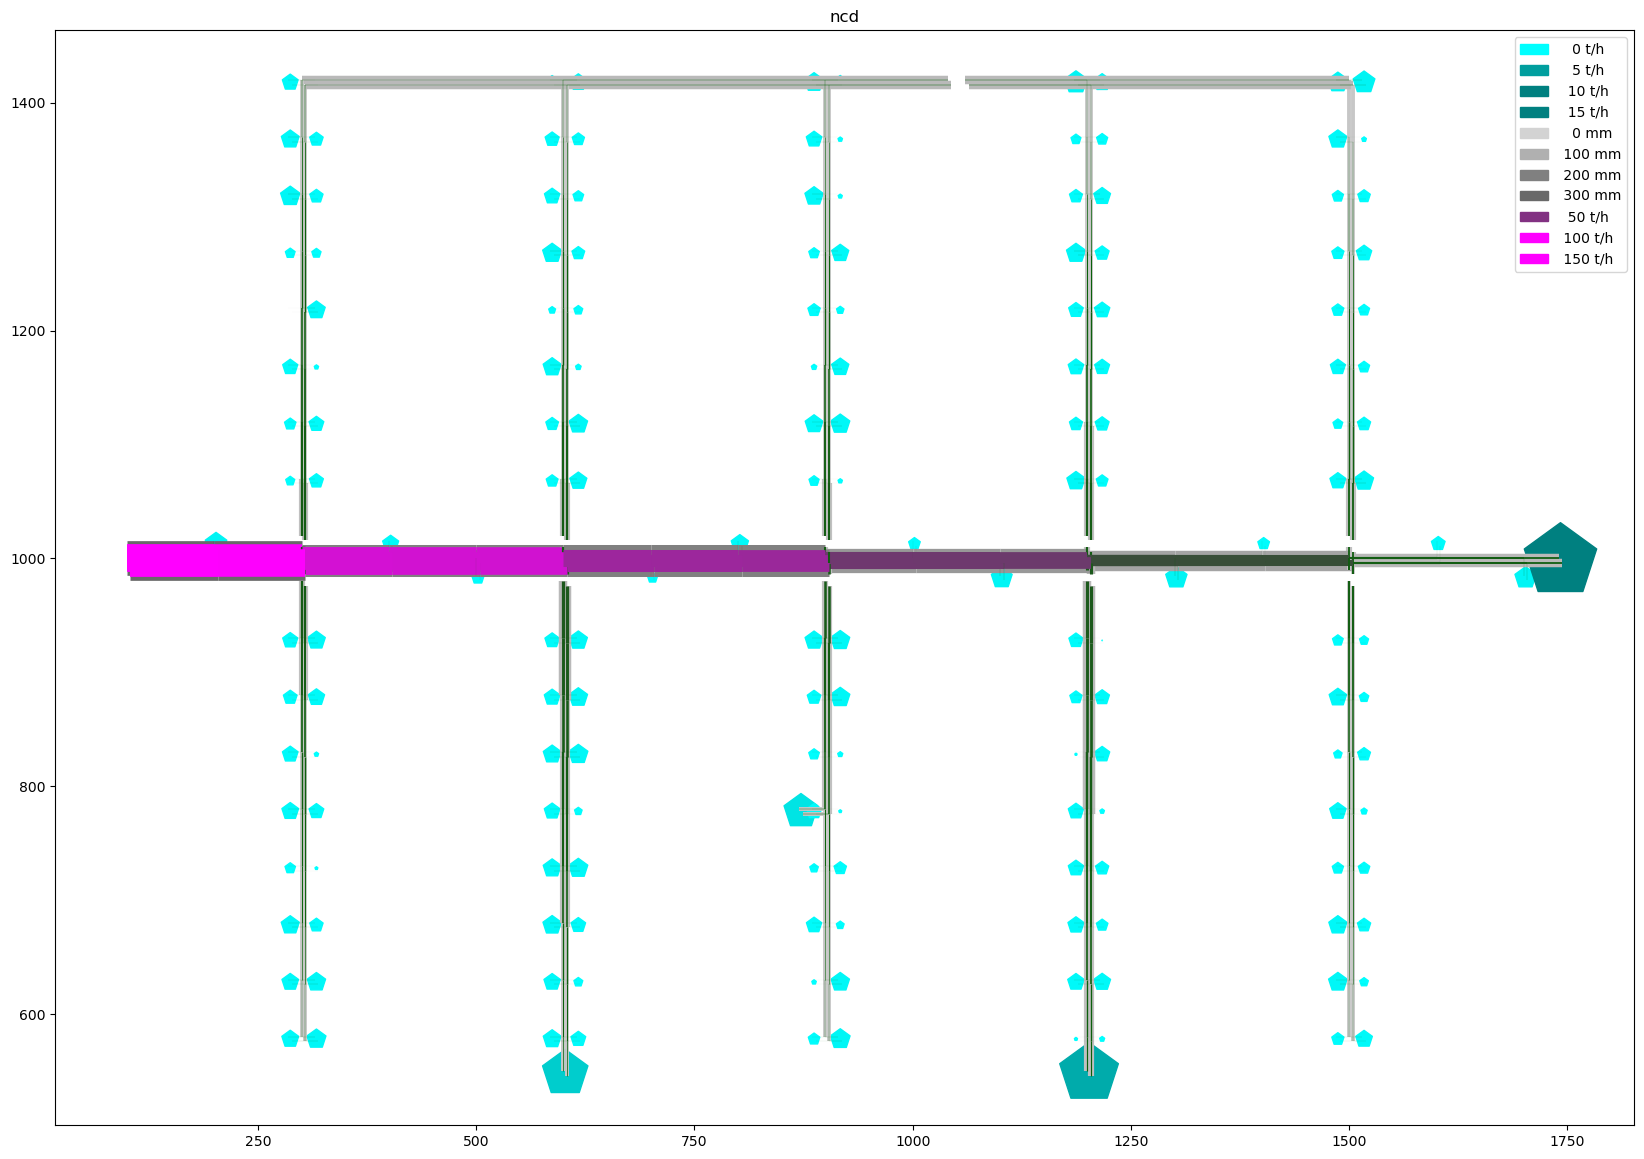

In [20]:
plot_Result_ncd(df_pipes, df_district_heating_consumer)